DATASET

In [ ]:
import pandas as pd
import numpy as np
from google.colab import files
import zipfile
import os

uploaded = files.upload()

# Get the uploaded zip file name
file_name = next(iter(uploaded))

# Extract zip file content to inspect
if file_name.endswith('.zip'):
    with zipfile.ZipFile(file_name, 'r') as zip_ref:
        zip_ref.extractall('cisi_data')
    print("Extracted files:", os.listdir('cisi_data'))
else:
    df = pd.read_csv(file_name)
    print("Dataset shape:", df.shape)
    display(df.head())


Saving archive.zip to archive.zip
Extracted files: ['CISI.REL', 'CISI.ALL', 'CISI.QRY']


In [ ]:
import os
import pandas as pd
from sklearn.feature_extraction.text import TfidfVectorizer

# Path to the extracted CISI documents file
cisi_all_path = 'cisi_data/CISI.ALL'

documents = []
with open(cisi_all_path, 'r', encoding='utf-8') as f:
    lines = f.readlines()

current_id = None
current_text = []
reading_text = False

for line in lines:
    if line.startswith(".I"):
        if current_id is not None:
            documents.append({
                "document_id": f"D{current_id}",
                "text": " ".join(current_text).strip()
            })
        current_id = line.strip().split()[1]
        current_text = []
        reading_text = False
    elif line.startswith(".T") or line.startswith(".A") or line.startswith(".W"):
        reading_text = True
    elif line.startswith(".X"):
        reading_text = False
    elif reading_text:
        current_text.append(line.strip())

# Append the last document
if current_id is not None:
    documents.append({
        "document_id": f"D{current_id}",
        "text": " ".join(current_text).strip()
    })

df = pd.DataFrame(documents)

TEXT_COLUMN = "text"
ID_COLUMN = "document_id"
LABEL_COLUMN = None  # No label column in standard CISI documents

# Remove missing and empty documents
df = df.dropna(subset=[TEXT_COLUMN]).copy()
df[TEXT_COLUMN] = df[TEXT_COLUMN].astype(str).str.strip()
df = df[df[TEXT_COLUMN] != ""].reset_index(drop=True)

# Convert text into TF-IDF features
vectorizer = TfidfVectorizer(
    stop_words="english",
    max_features=10000,
    ngram_range=(1, 2),
    min_df=1
)

X = vectorizer.fit_transform(df[TEXT_COLUMN])

print("Number of documents parsed:", X.shape[0])
print("Number of TF-IDF features:", X.shape[1])
display(df.head())


Number of documents parsed: 1460
Number of TF-IDF features: 10000


,document_id,text
0,D1,18 Editions of the Dewey Decimal Classificatio...
1,D2,"Use Made of Technical Libraries Slater, M. Thi..."
2,D3,Two Kinds of Power An Essay on Bibliographic C...
3,D4,Systems Analysis of a University Library; fina...
4,D5,A Library Management Game: a report on a resea...


In [ ]:
from sklearn.cluster import KMeans

# Choose the number of clusters
N_CLUSTERS = min(5, len(df))

if N_CLUSTERS < 2:
    raise ValueError("At least 2 documents are needed for clustering.")

kmeans = KMeans(
    n_clusters=N_CLUSTERS,
    random_state=42,
    n_init=10
)

df["cluster"] = kmeans.fit_predict(X)

# Distance to each document's assigned cluster centroid
distances = kmeans.transform(X)
df["cluster_distance"] = distances[
    np.arange(len(df)), df["cluster"].to_numpy()
]

# Within each cluster, rank the most representative documents first
df["cluster_rank"] = (
    df.groupby("cluster")["cluster_distance"]
      .rank(method="first", ascending=True)
      .astype(int)
)

print("Documents in each cluster:")
print(df["cluster"].value_counts().sort_index())

display(
    df[[ID_COLUMN, TEXT_COLUMN, "cluster",
        "cluster_distance", "cluster_rank"]].head(10)
)

Documents in each cluster:
cluster
0    240
1    238
2    391
3    236
4    355
Name: count, dtype: int64


,document_id,text,cluster,cluster_distance,cluster_rank
0,D1,18 Editions of the Dewey Decimal Classificatio...,2,0.995001,322
1,D2,"Use Made of Technical Libraries Slater, M. Thi...",1,0.963288,61
2,D3,Two Kinds of Power An Essay on Bibliographic C...,2,0.996155,337
3,D4,Systems Analysis of a University Library; fina...,4,0.967844,42
4,D5,A Library Management Game: a report on a resea...,3,0.994400,209
5,D6,"Abstracting Concepts and Methods Borko, H. Gra...",3,0.986032,158
6,D7,Academic Library Buildings A Guide to Architec...,4,0.979838,163
7,D8,The Academic Library Essays in Honor of Guy R....,4,0.964063,26
8,D9,"Access to Libraries in College Hyman, R.T. Thi...",4,0.983989,222
9,D10,"Access to Periodical Resources Palmour, V.E. T...",4,0.985798,248


In [ ]:
from sklearn.naive_bayes import MultinomialNB
from sklearn.svm import LinearSVC
from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)
from sklearn.calibration import CalibratedClassifierCV

models = {}
metrics = {}

has_labels = (
    LABEL_COLUMN is not None
    and LABEL_COLUMN in df.columns
)

if has_labels:
    # Remove rows with missing labels
    valid = df[LABEL_COLUMN].notna()
    labeled_df = df.loc[valid].copy()
    X_labeled = X[valid.to_numpy()]
    y = labeled_df[LABEL_COLUMN].to_numpy()

    if len(np.unique(y)) < 2:
        raise ValueError(
            "Naive Bayes and SVM need at least two label classes."
        )

    # Split only if each class has enough examples
    counts = pd.Series(y).value_counts()
    can_split = (
        len(y) >= 4
        and counts.min() >= 2
        and int(np.ceil(0.2 * len(y))) >= len(counts)
    )

    if can_split:
        X_train, X_test, y_train, y_test = train_test_split(
            X_labeled,
            y,
            test_size=0.2,
            random_state=42,
            stratify=y
        )

        nb_eval = MultinomialNB()
        svm_eval = LinearSVC(random_state=42)

        for name, model in [
            ("Naive Bayes", nb_eval),
            ("SVM", svm_eval)
        ]:
            model.fit(X_train, y_train)
            predictions = model.predict(X_test)

            metrics[name] = {
                "accuracy": accuracy_score(y_test, predictions),
                "report": classification_report(
                    y_test, predictions, zero_division=0
                ),
                "confusion_matrix": confusion_matrix(
                    y_test, predictions
                )
            }

            print(f"\n{name}")
            print("Accuracy:", metrics[name]["accuracy"])
            print(metrics[name]["report"])
            print("Confusion matrix:\n",
                  metrics[name]["confusion_matrix"])
    else:
        print(
            "Too few examples per class for a reliable "
            "train/test evaluation. Models will be fitted, "
            "but evaluation metrics are skipped."
        )

    # Fit final models on all labeled documents
    nb = MultinomialNB()
    nb.fit(X_labeled, y)

    # Calibrate SVM scores to obtain probability-like scores
    svm_base = LinearSVC(random_state=42)
    svm = CalibratedClassifierCV(svm_base, cv=2)
    svm.fit(X_labeled, y)

    models = {
        "Naive Bayes": nb,
        "SVM": svm
    }

else:
    print(
        "No label column found. K-Means is available, "
        "but supervised Naive Bayes and SVM ranking "
        "require labeled training documents."
    )

No label column found. K-Means is available, but supervised Naive Bayes and SVM ranking require labeled training documents.


In [ ]:
if has_labels:
    # CHANGE this to your actual relevant class
    POSITIVE_LABEL = 1

    for name, model in models.items():
        classes = list(model.classes_)

        if POSITIVE_LABEL not in classes:
            print(
                f"Skipping {name}: positive label "
                f"{POSITIVE_LABEL!r} is not in the training labels."
            )
            continue

        positive_index = classes.index(POSITIVE_LABEL)

        probabilities = model.predict_proba(X)
        df[f"{name.lower().replace(' ', '_')}_score"] = (
            probabilities[:, positive_index]
        )

        score_col = f"{name.lower().replace(' ', '_')}_score"
        df[f"{name.lower().replace(' ', '_')}_rank"] = (
            df[score_col]
            .rank(method="first", ascending=False)
            .astype(int)
        )

    # Combine the two model scores when both are available
    score_columns = [
        col for col in ["naive_bayes_score", "svm_score"]
        if col in df.columns
    ]

    if score_columns:
        df["combined_score"] = df[score_columns].mean(axis=1)

        ranked_df = df.sort_values(
            "combined_score", ascending=False
        ).reset_index(drop=True)

        ranked_df.insert(
            0, "final_rank", np.arange(1, len(ranked_df) + 1)
        )

        print("Top 10 ranked documents:")
        display(
            ranked_df[
                ["final_rank", ID_COLUMN, TEXT_COLUMN,
                 "cluster", *score_columns, "combined_score"]
            ].head(10)
        )
else:
    # Unlabeled dataset: rank representatives within each cluster.
    ranked_df = df.sort_values(
        ["cluster", "cluster_distance"],
        ascending=[True, True]
    ).reset_index(drop=True)

    ranked_df.insert(
        0, "representative_rank",
        ranked_df.groupby("cluster").cumcount() + 1
    )

    display(
        ranked_df[
            ["representative_rank", ID_COLUMN, TEXT_COLUMN,
             "cluster", "cluster_distance"]
        ].head(20)
    )

,representative_rank,document_id,text,cluster,cluster_distance
0,1,D1124,Some Aspects of Developing and Studying a Desc...,0,0.933589
1,2,D565,Computer Evaluation of Indexing and Text Proce...,0,0.942301
2,3,D894,An Experiment in Index Term Frequency Svenoniu...,0,0.946686
3,4,D660,"On Relevance, Probabilistic Indexing and Infor...",0,0.947675
4,5,D530,Indexing Language Structure for Automated Retr...,0,0.947745
5,6,D566,"Semantic Clustering of Index Terms Gotlieb, C....",0,0.949054
6,7,D489,Experiments in Book Indexing by Computer Borko...,0,0.950301
7,8,D446,"Computer Assisted Indexing Gray, W. A. The pap...",0,0.951729
8,9,D483,Performance of Automatic Information Systems L...,0,0.953077
9,10,D661,Is Automatic Classification a Reasonable Appli...,0,0.953733


In [ ]:
output_file = "ranked_documents.csv"

ranked_df.to_csv(output_file, index=False)

from google.colab import files
files.download(output_file)

print("Ranked document results exported successfully.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Ranked document results exported successfully.


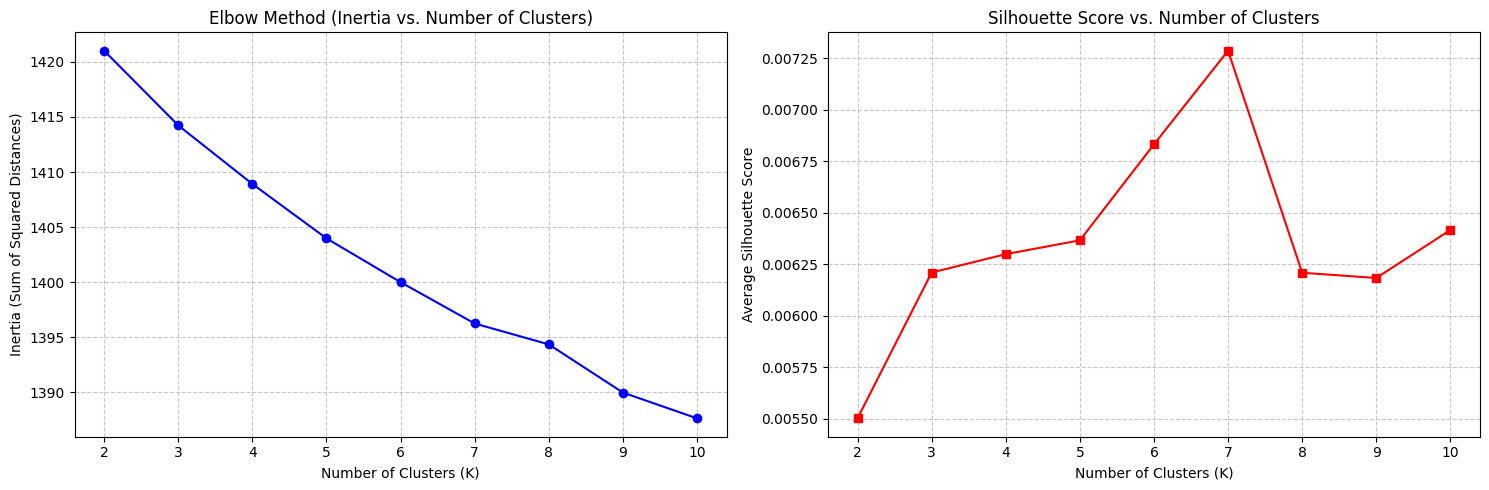

In [ ]:
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

# Evaluate K-Means for different values of K
cluster_range = range(2, 11)
inertias = []
silhouette_scores = []

for k in cluster_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X)
    inertias.append(km.inertia_)
    silhouette_scores.append(silhouette_score(X, labels))

# Plotting the evaluation graphs
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 5))

# Elbow Method (Inertia)
ax1.plot(cluster_range, inertias, marker='o', color='b', linestyle='-')
ax1.set_title('Elbow Method (Inertia vs. Number of Clusters)')
ax1.set_xlabel('Number of Clusters (K)')
ax1.set_ylabel('Inertia (Sum of Squared Distances)')
ax1.grid(True, linestyle='--', alpha=0.7)

# Silhouette Score
ax2.plot(cluster_range, silhouette_scores, marker='s', color='r', linestyle='-')
ax2.set_title('Silhouette Score vs. Number of Clusters')
ax2.set_xlabel('Number of Clusters (K)')
ax2.set_ylabel('Average Silhouette Score')
ax2.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()
